# 3. Implicit Q-Learning (IQL)

Código: `src/iql.py`. Barrido: `python -m src.experimentos iql_sweep`. Entrenamiento final: `iql_train` (3 semillas).

## 3.1 Componentes

| Red | Qué estima | Cómo se entrena |
|---|---|---|
| V(s) | valor del estado | regresión de **expectil** τ sobre $\bar Q(s, a)$ de la acción registrada: $L_V = E[\,|τ − 1(u<0)|\,u^2]$, con $u = \bar Q(s,a) − V(s)$ |
| Q(s, a) | valor de mostrar a en s | **TD**: $Q(s_t,a_t) \leftarrow r_t + γ\,V(s_{t+1})$. En el último paso (t = 19), sólo $r_t$ |
| π(a \| s) | política | **AWR**: cross-entropy de la acción registrada, ponderada por $\min(e^{β(\bar Q − V)}, 100)$ |
| $\bar Q$ | red objetivo | copia de Q con promedio de Polyak, λ = 0,005 por paso |

**Decisiones:**
- **Estado:** GRU sobre los pares (ítem, rating) previos, más el embedding del grupo (o "desconocido") y del paso. Devuelve $h_0 … h_{20}$. Q(s_t, a_t) se lee de $h_t$ y V(s_{t+1}) de $h_{t+1}$.
- **Codificadores:** Q, V y π tienen **cada una su propio codificador**. Así cada pérdida entrena sólo su red y no hay que decidir qué pérdida entrena un codificador compartido.
- **Gradientes separados:** V(s') entra al objetivo de Q sin gradiente; los pesos de AWR se calculan sin gradiente; el objetivo de V usa $\bar Q$ sin gradiente. Esto está verificado en `tests/test_modelos.py`.
- **Recompensa centrada:** (r − 3)/2 ∈ [−1, 1]. No cambia qué acción es mejor; fija la escala de Q, V y de las ventajas, y por lo tanto el efecto de β.
- **Ítems ya mostrados:** se enmascaran en π al entrenar. Al recomendar, el protocolo los descarta tanto para π como para el máximo de Q.
- **Grupo oculto:** en el 30 % de los episodios de train el grupo se reemplaza por "desconocido".
- **Optimización:** Adam lr 1e-3 (uno por red), lotes de 256, 5 épocas, d = 64.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from src.utils import OUTPUTS
from src import reporte
pd.set_option("display.width", 200)

## 3.2 Barrido en validación: τ, β y γ

Se eligen con el **protocolo** en validación (normalizado medio de π, warm-up 0, grupo visible y oculto), no con las pérdidas.

In [2]:
sw = pd.read_csv(OUTPUTS / "seleccion" / "iql_random_val.csv")
tab = sw.pivot_table(index=["gamma", "tau", "beta"], columns=["mode", "group_visible"], values="normalized")
tab.columns = [f"{'π' if m == 'pi' else 'máx Q'} {'visible' if v else 'oculto'}" for m, v in tab.columns]
tab["π media"] = tab[["π visible", "π oculto"]].mean(axis=1)
display(tab.round(3).sort_values("π media", ascending=False))
elegido = reporte.load_json("seleccion/iql_random_elegido.json")
print("elegido:", elegido)

π oculto  π visible  máx Q oculto  máx Q visible  π media
gamma tau beta                                                           
0.9   0.7 10.0     0.555      0.644         0.549          0.636    0.600
0.0   0.7 10.0     0.552      0.647         0.560          0.647    0.599
0.9   0.7 3.0      0.553      0.644         0.549          0.636    0.598
0.0   0.7 3.0      0.548      0.646         0.560          0.647    0.597
0.9   0.9 3.0      0.552      0.643         0.541          0.634    0.597
          10.0     0.553      0.641         0.541          0.634    0.597
0.0   0.9 10.0     0.550      0.643         0.560          0.647    0.596
          3.0      0.546      0.645         0.560          0.647    0.595

elegido: {'gamma': 0.9, 'tau': 0.7, 'beta': 10.0, 'val_normalized_pi': 0.5998268118261115, 'mejor_tau_beta_por_gamma': {'0.0': [0.7, 10.0], '0.9': [0.7, 10.0]}, 'criterio': 'media de normalizado de π en val (warm-up 0, grupo visible y oculto, semilla 0)'}


## 3.3 Curvas de entrenamiento (configuración elegida, 3 semillas)

semilla 0: pesos truncados en 100 = 5.04 %, ventaja media -0.132 (desvío 0.392)
semilla 1: pesos truncados en 100 = 4.93 %, ventaja media -0.132 (desvío 0.390)
semilla 2: pesos truncados en 100 = 4.91 %, ventaja media -0.134 (desvío 0.394)


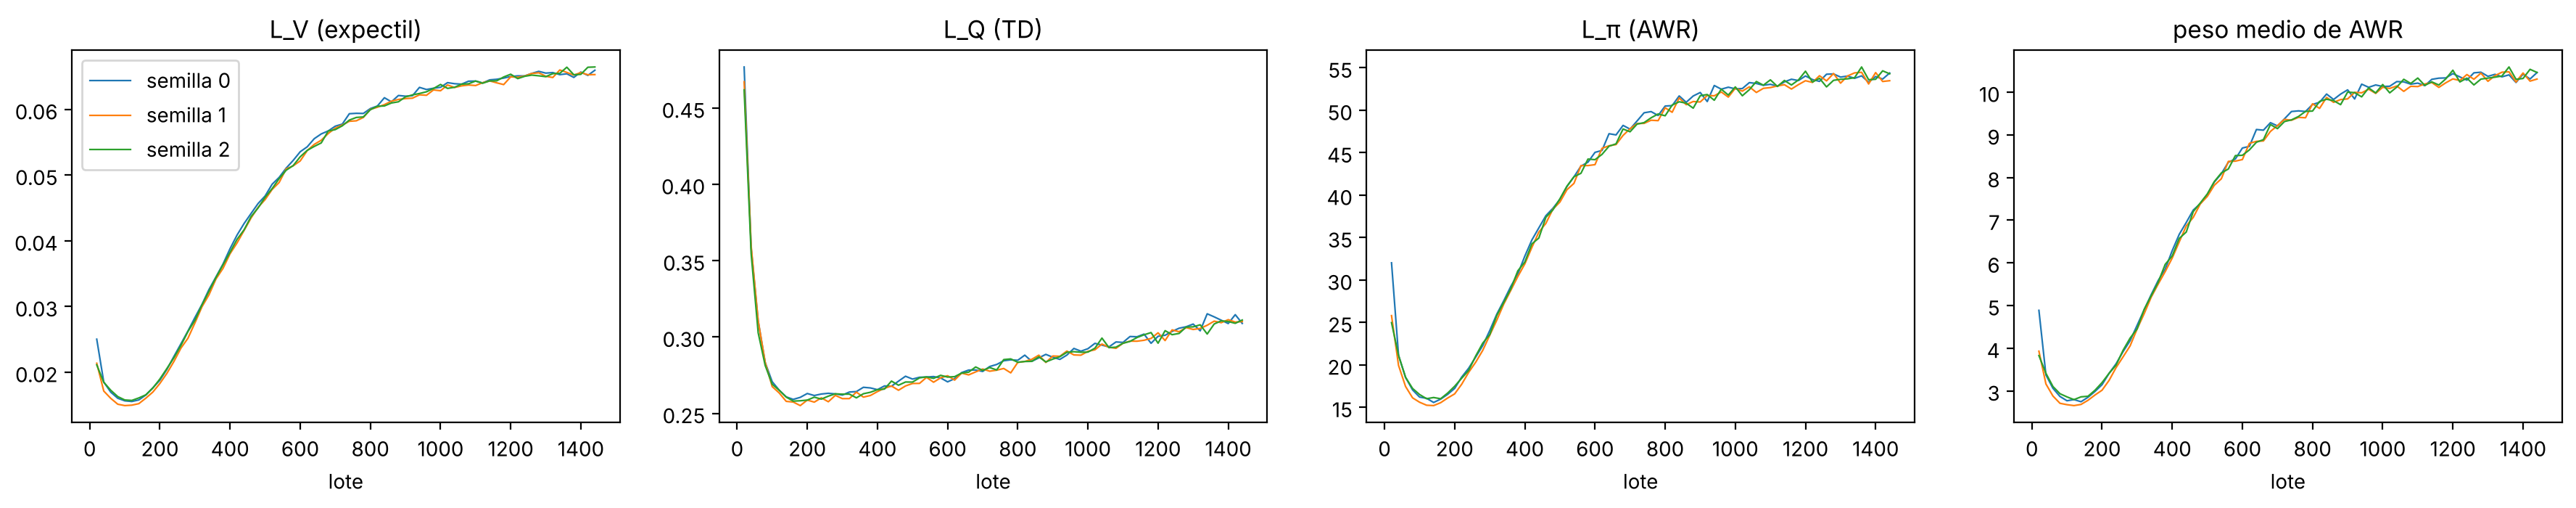

In [3]:
g, t, b = elegido["gamma"], elegido["tau"], elegido["beta"]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for s in (0, 1, 2):
    h = json.loads((OUTPUTS / "iql" / "random" / f"g{g}_t{t}_b{b}" / f"seed{s}" / "history.json").read_text())
    for ax, k, title in zip(axes, ["loss_v", "loss_q", "loss_pi", "w_mean"],
                            ["L_V (expectil)", "L_Q (TD)", "L_π (AWR)", "peso medio de AWR"]):
        ax.plot(h["step"], h[k], lw=0.8, label=f"semilla {s}"); ax.set(title=title, xlabel="lote")
    print(f"semilla {s}: pesos truncados en 100 = {100 * h['w_clipped'][-1]:.2f} %, "
          f"ventaja media {h['adv_mean'][-1]:.3f} (desvío {h['adv_std'][-1]:.3f})")
axes[0].legend(); plt.tight_layout(); plt.show()

**Lectura de las curvas:**
- $L_V$ **sube** al principio. Mientras Q aprende a separar ítems buenos de malos, aparecen diferencias $\bar Q − V$ más grandes, y el expectil las persigue.
- $L_Q$ baja hasta un piso: el ruido del rating no se puede predecir.
- $L_π$ es una cross-entropy ponderada. Sube a medida que los pesos se vuelven más selectivos, y eso **no** indica que π empeore (rúbrica: las pérdidas de Q y π pueden subir mientras la política mejora).
- Peso medio y porcentaje truncado: si casi todos los pesos estuvieran en 100, β sería demasiado grande; si todos valieran ≈ 1, π sería behavior cloning.

## 3.4 γ = 0 frente a γ = 0,9, y π frente al máximo de Q (test, 3 semillas)

In [4]:
t_all = reporte.main_table("random")
rows = [r for r in t_all.index if r.startswith("iql")]
display(t_all.loc[rows])
print("formato: media entre 3 semillas ± desvío entre semillas [± IC 95 % por usuario]")

condición,visible,oculto,"warm-up 5, visible","warm-up 5, oculto"
policy,,,,
iql_pi,0.697 ± 0.002 [±0.006],0.631 ± 0.029 [±0.006],0.704 ± 0.001 [±0.006],0.666 ± 0.028 [±0.006]
iql_maxq,0.705 ± 0.004 [±0.005],0.616 ± 0.008 [±0.005],0.713 ± 0.004 [±0.005],0.652 ± 0.008 [±0.005]
iql_pi_gamma0.0,0.700 ± 0.004 [±0.006],0.625 ± 0.024 [±0.006],0.701 ± 0.003 [±0.007],0.672 ± 0.017 [±0.005]
iql_maxq_gamma0.0,0.719 ± 0.003 [±0.005],0.637 ± 0.004 [±0.005],0.729 ± 0.002 [±0.005],0.671 ± 0.005 [±0.005]


formato: media entre 3 semillas ± desvío entre semillas [± IC 95 % por usuario]


**γ = 0 frente a γ > 0.** Con γ = 0, Q(s, a) sólo predice el rating inmediato: es un **bandit contextual**. Con γ = 0,9, Q suma además el valor de lo que viene después. En este dataset el rating no depende de lo que se mostró antes, así que el único valor futuro posible es **informativo**: un rating revelado ayuda a inferir el grupo cuando está oculto. Con grupo visible no hay nada que ganar con la secuencia, y la diferencia esperada es ≈ 0. Ver los números arriba y la discusión en `docs/REPORTE.md`.

**π frente al máximo de Q.** π se entrena sólo con acciones registradas, ponderadas por su ventaja, y por eso se queda **dentro del soporte** de los datos. El máximo de Q elige el ítem de mayor Q entre **todos**, incluidos los que la red estima mal: es el error de extrapolación que IQL evita al entrenar. Acá los logs son uniformes y cubren todos los ítems de forma pareja (cada ítem aparece unas 2.000 veces), así que Q está bien estimada en todo el catálogo y el máximo de Q **no** sufre extrapolación. Por eso puede rendir igual o mejor que π, que además arrastra el ruido de la cross-entropy ponderada.

## 3.5 Diagnóstico: rating medio en cada paso de la sesión

Para entender dónde gana o pierde cada política, se mide el rating medio obtenido en cada uno de los 20 pasos (test, warm-up 0, semilla de entrenamiento 0, semilla de evaluación 0).

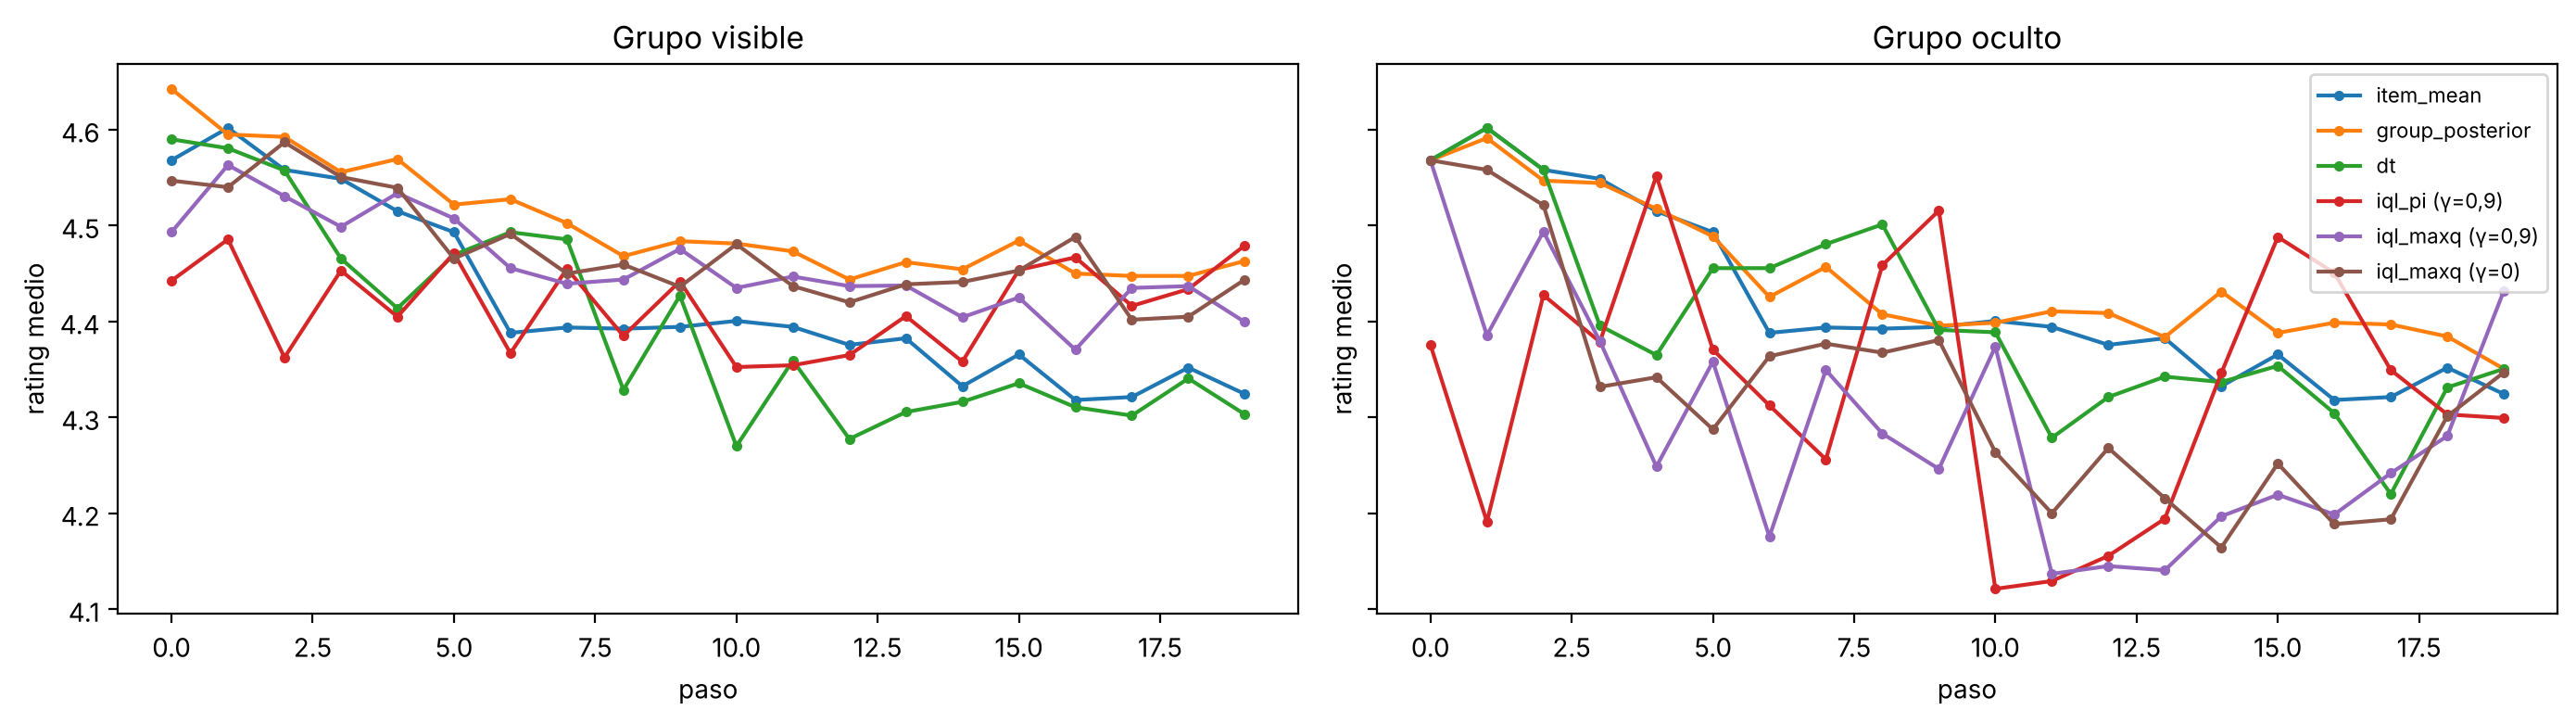

0     1     2     4     9     19
True  item_mean         4.57  4.60  4.56  4.51  4.39  4.32
      group_posterior   4.64  4.60  4.59  4.57  4.48  4.46
      dt                4.59  4.58  4.56  4.41  4.43  4.30
      iql_pi (γ=0,9)    4.44  4.49  4.36  4.40  4.44  4.48
      iql_maxq (γ=0,9)  4.49  4.56  4.53  4.53  4.48  4.40
      iql_maxq (γ=0)    4.55  4.54  4.59  4.54  4.44  4.44
False item_mean         4.57  4.60  4.56  4.51  4.39  4.32
      group_posterior   4.57  4.59  4.55  4.52  4.40  4.35
      dt                4.57  4.60  4.56  4.36  4.39  4.35
      iql_pi (γ=0,9)    4.38  4.19  4.43  4.55  4.52  4.30
      iql_maxq (γ=0,9)  4.57  4.39  4.49  4.25  4.25  4.43
      iql_maxq (γ=0)    4.57  4.56  4.52  4.34  4.38  4.35

In [5]:
from protocolo.datos import load_train, load_test, split_by_user
from protocolo.evaluar import baseline_factories
from protocolo.simulador import SessionConfig
from src.utils import per_step_rewards, BaselineBatch
from src.iql import IQLPolicy
from src.dt import DTPolicy
from src.experimentos import load_iql, load_dt, iql_dir, IQL_DEFAULT
from src.iql import IQLConfig
train, _ = split_by_user(load_train("netflix")); test = load_test("netflix")
bf = baseline_factories(train, 752)
g, t, b = elegido["gamma"], elegido["tau"], elegido["beta"]
iql9, _ = load_iql(iql_dir("random", IQLConfig(**IQL_DEFAULT, gamma=g, tau=t, beta=b, seed=0)), 752)
tb0 = elegido["mejor_tau_beta_por_gamma"]["0.0"]
iql0, _ = load_iql(iql_dir("random", IQLConfig(**IQL_DEFAULT, gamma=0.0, tau=tb0[0], beta=tb0[1], seed=0)), 752)
dt_target = reporte.load_json("seleccion/dt_random_elegido.json")["target"]
pols = {"item_mean": BaselineBatch(bf["item_mean"]), "group_posterior": BaselineBatch(bf["group_posterior"]),
        "dt": DTPolicy(load_dt("random", 0, 752), dt_target),
        "iql_pi (γ=0,9)": IQLPolicy(iql9, "pi"), "iql_maxq (γ=0,9)": IQLPolicy(iql9, "q"), "iql_maxq (γ=0)": IQLPolicy(iql0, "q")}
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
steps = {}
for vis, ax in zip([True, False], axes):
    for name, p in pols.items():
        r = per_step_rewards(p, test, 752, SessionConfig(20, 0, vis), seed=0)
        steps[(vis, name)] = r.mean(0)
        ax.plot(range(20), r.mean(0), marker=".", label=name)
    ax.set(title=f"Grupo {'visible' if vis else 'oculto'}", xlabel="paso", ylabel="rating medio")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
display(pd.DataFrame({k: v for k, v in steps.items()}).T.iloc[:, [0, 1, 2, 4, 9, 19]].round(2))

**Lectura.** Las curvas muestran en qué pasos cada política gana o pierde rating respecto de `item_mean` (que no cambia con el paso) y de `group_posterior` (que mejora a medida que infiere el grupo). La interpretación está en `docs/REPORTE.md`.